# Nykaa Demand Forecasting (Beginner Project)
**Goal:** predict how many units of a product Nykaa will sell in a city on a given day, so we know how much stock to keep.

**Before you start:** upload `Nykaa_Demand.csv` using the folder icon on the left (Files) -> upload button.
Run each cell with **Shift + Enter**, from top to bottom.

## Step 1: Import libraries
These are tools: pandas (tables), numpy (maths), matplotlib/seaborn (charts), sklearn/xgboost (machine learning).

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

import warnings
warnings.filterwarnings('ignore')

## Step 2: Load the data
Each row = one product, in one city, on one day, with the units sold that day.

In [11]:
df = pd.read_csv('sample_data/Nykaa_Demand.csv', parse_dates=['date'])

# Pandas reads the word "None" as an empty value, so we rename it
df['festival'] = df['festival'].fillna('No Festival')

# If you uploaded to Google Drive instead, use:
# from google.colab import drive; drive.mount('/content/drive')
# df = pd.read_csv('/content/drive/MyDrive/Nykaa_Demand.csv', parse_dates=['date'])
df.head()

,date,city,product,category,price,discount_pct,festival,units_sold
0,2022-01-01,Mumbai,Lipstick,Makeup,599,0,No Festival,104
1,2022-01-02,Mumbai,Lipstick,Makeup,599,0,No Festival,103
2,2022-01-03,Mumbai,Lipstick,Makeup,599,0,No Festival,109
3,2022-01-04,Mumbai,Lipstick,Makeup,599,0,No Festival,92
4,2022-01-05,Mumbai,Lipstick,Makeup,599,0,No Festival,95


In [12]:
print(df.shape)          # (rows, columns)
print(df.isnull().sum())  # missing values (should be 0)
df.info()

(21915, 8)
date            0
city            0
product         0
category        0
price           0
discount_pct    0
festival        0
units_sold      0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21915 entries, 0 to 21914
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          21915 non-null  datetime64[ns]
 1   city          21915 non-null  object        
 2   product       21915 non-null  object        
 3   category      21915 non-null  object        
 4   price         21915 non-null  int64         
 5   discount_pct  21915 non-null  int64         
 6   festival      21915 non-null  object        
 7   units_sold    21915 non-null  int64         
dtypes: datetime64[ns](1), int64(3), object(4)
memory usage: 1.3+ MB


In [13]:
df.describe()

,date,price,discount_pct,units_sold
count,21915,21915.000000,21915.000000,21915.000000
mean,2024-01-01 00:00:00,789.000000,4.545289,73.177185
min,2022-01-01 00:00:00,399.000000,0.000000,9.000000
25%,2023-01-01 00:00:00,599.000000,0.000000,45.000000
50%,2024-01-01 00:00:00,749.000000,0.000000,65.000000
75%,2024-12-31 00:00:00,899.000000,10.000000,91.000000
max,2025-12-31 00:00:00,1299.000000,25.000000,370.000000
std,NaN,303.980619,6.159644,40.312516


In [14]:
print(df['product'].unique())
print(df['city'].unique())
print(df['festival'].unique())
print(df['date'].min(), 'to', df['date'].max())

['Lipstick' 'Foundation' 'Face Serum' 'Shampoo' 'Perfume']
['Mumbai' 'Bhopal' 'Bengaluru']
['No Festival' 'Republic Day Sale' 'Holi' 'Eid' 'Independence Day Sale'
 'Big Billion Days' 'Diwali' 'Pink Friday Sale' 'Christmas']
2022-01-01 00:00:00 to 2025-12-31 00:00:00


## Step 3: Explore the data (EDA)
We draw charts to understand patterns. **Write your own 4-5 insights in a text cell after this step.**

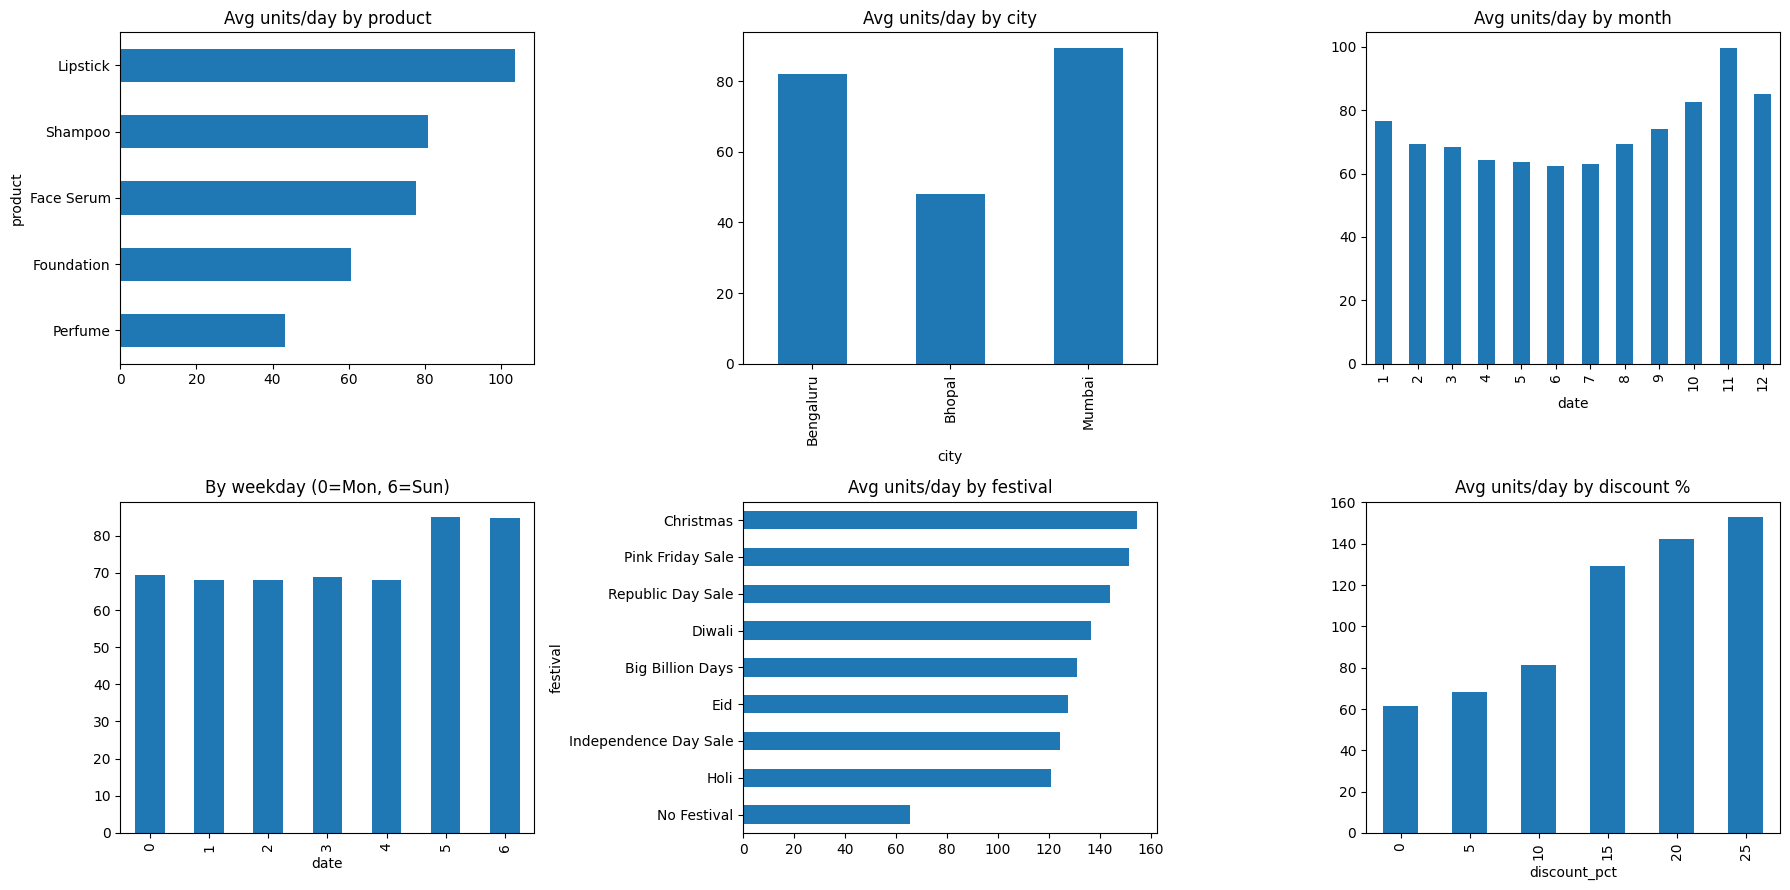

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

df.groupby('product')['units_sold'].mean().sort_values().plot.barh(ax=axes[0,0], title='Avg units/day by product')
df.groupby('city')['units_sold'].mean().plot.bar(ax=axes[0,1], title='Avg units/day by city')
df.groupby(df['date'].dt.month)['units_sold'].mean().plot.bar(ax=axes[0,2], title='Avg units/day by month')
df.groupby(df['date'].dt.weekday)['units_sold'].mean().plot.bar(ax=axes[1,0], title='By weekday (0=Mon, 6=Sun)')
df.groupby('festival')['units_sold'].mean().sort_values().plot.barh(ax=axes[1,1], title='Avg units/day by festival')
df.groupby('discount_pct')['units_sold'].mean().plot.bar(ax=axes[1,2], title='Avg units/day by discount %')

plt.tight_layout()
plt.show()

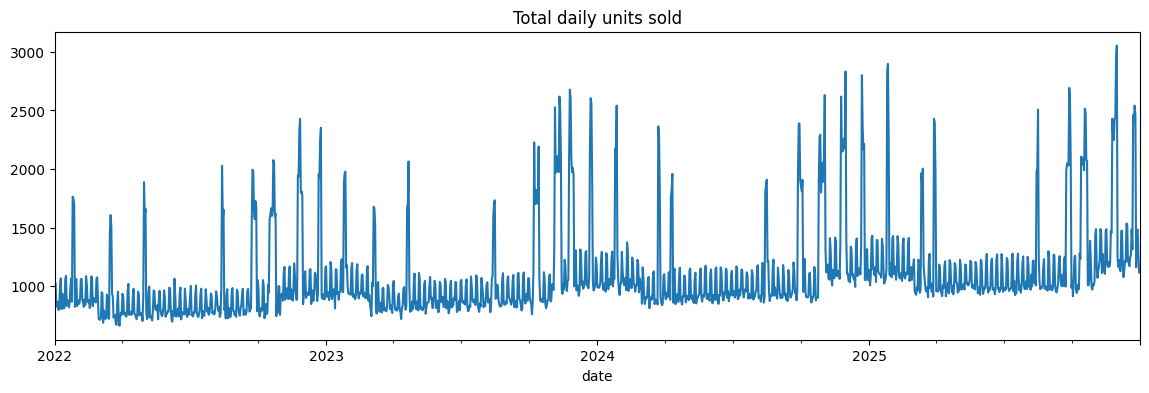

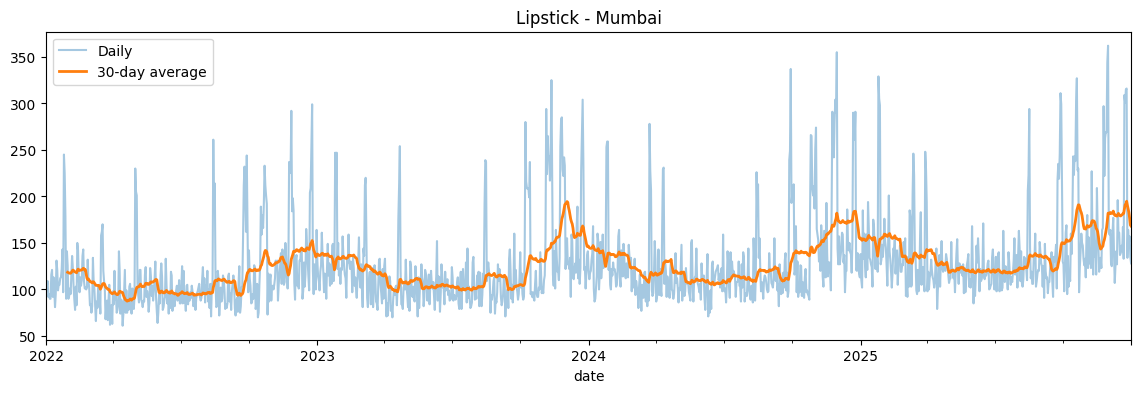

In [16]:
# Total daily sales over time (all products, all cities)
df.groupby('date')['units_sold'].sum().plot(figsize=(14, 4), title='Total daily units sold')
plt.show()

# One product in one city, with a 30-day moving average
one = df[(df['product'] == 'Lipstick') & (df['city'] == 'Mumbai')].set_index('date')['units_sold']
plt.figure(figsize=(14, 4))
one.plot(alpha=0.4, label='Daily')
one.rolling(30).mean().plot(label='30-day average', linewidth=2)
plt.title('Lipstick - Mumbai')
plt.legend()
plt.show()

## Step 4: Feature engineering
A model only understands numbers, so we turn dates and text into useful numbers:
- **date features**: month, day, weekday, weekend
- **is_festival**: 1 if any festival/sale is running
- **lag features**: sales 7, 14, 28 days ago and recent averages (the best clue for tomorrow's sales is the recent past)
- **codes**: city and product converted to numbers

In [17]:
data = df.sort_values(['city', 'product', 'date']).reset_index(drop=True)

# Date features
data['year'] = data['date'].dt.year
data['month'] = data['date'].dt.month
data['day'] = data['date'].dt.day
data['weekday'] = data['date'].dt.weekday
data['weekend'] = (data['weekday'] >= 5).astype(int)
data['m_sin'] = np.sin(data['month'] * 2 * np.pi / 12)
data['m_cos'] = np.cos(data['month'] * 2 * np.pi / 12)

# Festival flag
data['is_festival'] = (data['festival'] != 'No Festival').astype(int)

# Lag features (calculated separately for every city + product)
g = data.groupby(['city', 'product'])['units_sold']
data['lag_7'] = g.shift(7)
data['lag_14'] = g.shift(14)
data['lag_28'] = g.shift(28)
data['roll_mean_7'] = g.transform(lambda s: s.shift(1).rolling(7).mean())
data['roll_mean_28'] = g.transform(lambda s: s.shift(1).rolling(28).mean())

# Text -> numbers
city_map = {c: i for i, c in enumerate(sorted(data['city'].unique()))}
product_map = {p: i for i, p in enumerate(sorted(data['product'].unique()))}
data['city_code'] = data['city'].map(city_map)
data['product_code'] = data['product'].map(product_map)

# First 28 days of each series have no lag values -> drop them
data = data.dropna(subset=['lag_7', 'lag_14', 'lag_28', 'roll_mean_7', 'roll_mean_28']).reset_index(drop=True)

features = ['city_code', 'product_code', 'discount_pct', 'is_festival',
            'month', 'day', 'weekday', 'weekend', 'm_sin', 'm_cos',
            'lag_7', 'lag_14', 'lag_28', 'roll_mean_7', 'roll_mean_28']

print(city_map)
print(product_map)
data[features + ['units_sold']].head()

{'Bengaluru': 0, 'Bhopal': 1, 'Mumbai': 2}
{'Face Serum': 0, 'Foundation': 1, 'Lipstick': 2, 'Perfume': 3, 'Shampoo': 4}


,city_code,product_code,discount_pct,is_festival,month,day,weekday,weekend,m_sin,m_cos,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_28,units_sold
0,0,0,5,0,1,29,5,1,0.500000,0.866025,69.0,105.0,87.0,100.142857,83.071429,72
1,0,0,0,0,1,30,6,1,0.500000,0.866025,70.0,101.0,97.0,100.571429,82.535714,75
2,0,0,0,0,1,31,0,0,0.500000,0.866025,72.0,71.0,66.0,101.285714,81.750000,63
3,0,0,0,0,2,1,1,0,0.866025,0.500000,117.0,83.0,96.0,100.000000,81.642857,83
4,0,0,0,0,2,2,2,0,0.866025,0.500000,133.0,62.0,73.0,95.142857,81.178571,76


## Step 5: Train / test split (by time!)
In real life we predict the **future** from the **past**, so: train on 2022-2024, test on 2025.
(A random split would let the model "peek" into the future and give fake-good results.)

In [18]:
train = data[data['year'] < 2025]
test = data[data['year'] == 2025]

X_train, y_train = train[features], train['units_sold']
X_test, y_test = test[features], test['units_sold']

print('Train rows:', X_train.shape[0], '| Test rows:', X_test.shape[0])

Train rows: 16020 | Test rows: 5475


## Step 6: Train models and compare
**MAE** = average mistake in units (lower is better). We also add a *naive baseline*: "next week = same as last week". A good model must beat it.

In [19]:
def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {'Model': name, 'MAE': round(mae, 2), 'RMSE': round(rmse, 2), 'R2': round(r2, 3)}

results = []

# Baseline: same as 7 days ago
results.append(evaluate('Naive (last week)', y_test, X_test['lag_7']))

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    results.append(evaluate(name, y_test, model.predict(X_test)))

pd.DataFrame(results).sort_values('MAE')

,Model,MAE,RMSE,R2
4,XGBoost,8.53,11.33,0.934
3,Random Forest,8.76,11.86,0.928
2,Ridge,10.94,16.06,0.868
1,Linear Regression,10.94,16.06,0.868
0,Naive (last week),25.14,41.30,0.124


## Step 7: Look at the predictions
Charts make results easy to understand (and look great in your README).

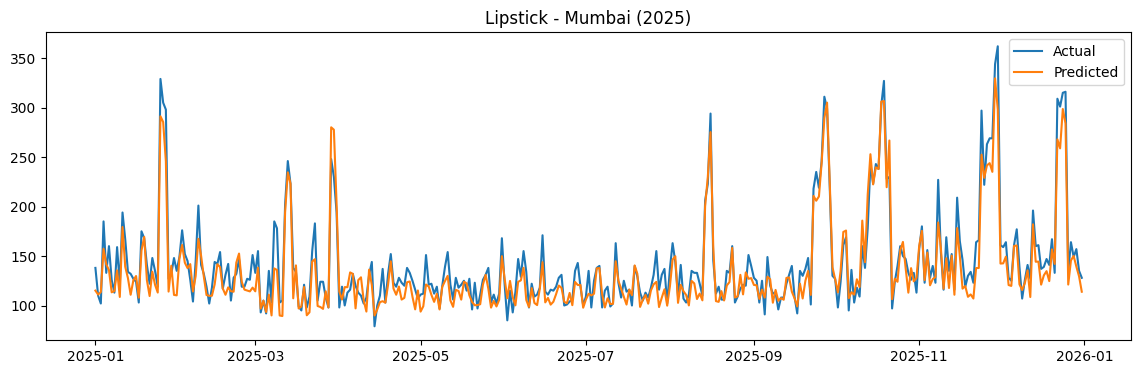

In [20]:
best = models['XGBoost']
test = test.copy()
test['pred'] = best.predict(X_test)

# Lipstick in Mumbai: actual vs predicted
one = test[(test['product'] == 'Lipstick') & (test['city'] == 'Mumbai')]
plt.figure(figsize=(14, 4))
plt.plot(one['date'], one['units_sold'], label='Actual')
plt.plot(one['date'], one['pred'], label='Predicted')
plt.title('Lipstick - Mumbai (2025)')
plt.legend()
plt.show()

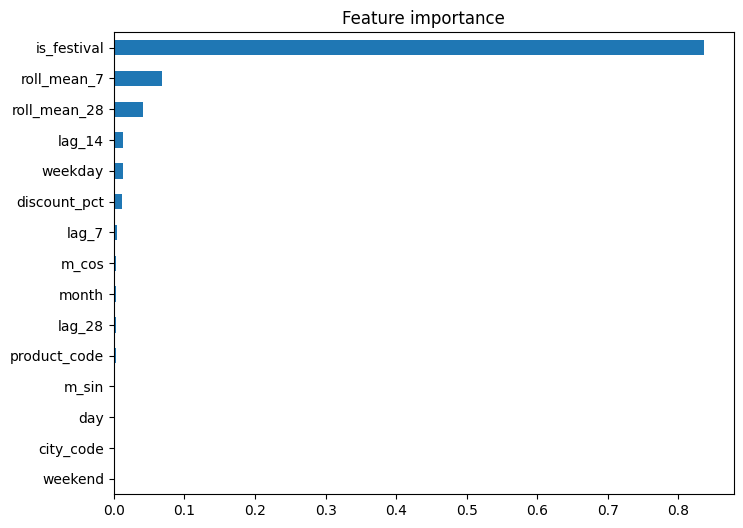

In [21]:
# Which features matter most?
pd.Series(best.feature_importances_, index=features).sort_values().plot.barh(figsize=(8, 6), title='Feature importance')
plt.show()

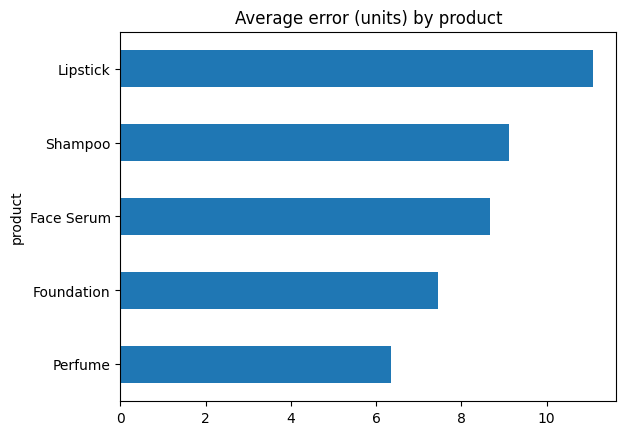

In [22]:
# Error per product
test['abs_error'] = (test['units_sold'] - test['pred']).abs()
test.groupby('product')['abs_error'].mean().sort_values().plot.barh(title='Average error (units) by product')
plt.show()

## Step 8: Train the final model on ALL data and save it
We checked that the model works, so now we train it on everything (more data = better) and **save it** so our web app can use it later.

In [23]:
final_model = XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42)
final_model.fit(data[features], data['units_sold'])

final_model.save_model('nykaa_xgb.json')

meta = {'features': features, 'city_map': city_map, 'product_map': product_map}
with open('nykaa_meta.json', 'w') as f:
    json.dump(meta, f)

print('Saved: nykaa_xgb.json and nykaa_meta.json')

Saved: nykaa_xgb.json and nykaa_meta.json


In [24]:
from google.colab import files
files.download('nykaa_xgb.json')
files.download('nykaa_meta.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 9: Forecast the future + reorder alert
Our model needs yesterday's sales to predict today, so to forecast 14 days we predict day 1, add it to history, predict day 2, and so on. This is called **recursive forecasting**.

In [25]:
def forecast(df_raw, model, meta, city, product, days=14, festival_days=0, sale_discount=0):
    hist = df_raw[(df_raw['city'] == city) & (df_raw['product'] == product)].sort_values('date')
    values = list(hist['units_sold'].values)
    last_date = hist['date'].max()
    rows = []
    for i in range(1, days + 1):
        d = last_date + pd.Timedelta(days=i)
        is_fest = 1 if i <= festival_days else 0
        disc = sale_discount if is_fest else 0
        month, weekday = d.month, d.weekday()
        x = {
            'city_code': meta['city_map'][city],
            'product_code': meta['product_map'][product],
            'discount_pct': disc,
            'is_festival': is_fest,
            'month': month, 'day': d.day, 'weekday': weekday,
            'weekend': int(weekday >= 5),
            'm_sin': np.sin(month * 2 * np.pi / 12),
            'm_cos': np.cos(month * 2 * np.pi / 12),
            'lag_7': values[-7], 'lag_14': values[-14], 'lag_28': values[-28],
            'roll_mean_7': np.mean(values[-7:]),
            'roll_mean_28': np.mean(values[-28:]),
        }
        pred = max(0.0, float(model.predict(pd.DataFrame([x])[meta['features']])[0]))
        values.append(pred)
        rows.append({'date': d, 'predicted_units': round(pred)})
    return pd.DataFrame(rows)

fc = forecast(df, final_model, meta, city='Mumbai', product='Lipstick', days=14)
fc

,date,predicted_units
0,2026-01-01,137
1,2026-01-02,126
2,2026-01-03,156
3,2026-01-04,155
4,2026-01-05,129
5,2026-01-06,124
6,2026-01-07,124
7,2026-01-08,124
8,2026-01-09,119
9,2026-01-10,161


In [26]:
# Reorder alert
current_stock = 600   # change this number
total_demand = fc['predicted_units'].sum()
safety_stock = int(0.10 * total_demand)   # 10% extra, just in case
reorder_qty = max(0, total_demand + safety_stock - current_stock)

print('Predicted demand (14 days):', total_demand)
print('Current stock:', current_stock)
print('Suggested reorder quantity:', reorder_qty)

Predicted demand (14 days): 1886
Current stock: 600
Suggested reorder quantity: 1474


## Done!
Next: download `nykaa_xgb.json` and `nykaa_meta.json`, put them in a GitHub repo with `app.py`, `requirements.txt` and `Nykaa_Demand.csv`, and deploy with Streamlit Community Cloud.